In [18]:
import numpy as np
from scipy.integrate import odeint
from scipy.optimize import fsolve
import matplotlib.pyplot as plt
from functools import partial
import sdeint

sdeint solve SDE of the form: dx = f(x, t) dt + G(x, t) dW_t

In [19]:
# f

def f(x, t, nu, kappa, lambda_r, lambda_c):
    r = x[0]
    theta = x[1]

    f_r = r * (lambda_r + nu * r**2)
    f_theta = lambda_c + kappa * r**2

    f = np.array((f_r, f_theta))

    return f

In [20]:
# G

def G(x, t, epsilon):
    r = x[0]
    theta = x[1]

    G_r_1 = epsilon * r
    G_r_2 = 0
    G_theta_1 = 0
    G_theta_2 = 0

    G = np.array([[G_r_1, G_r_2], [G_theta_1, G_theta_2]])

    return G

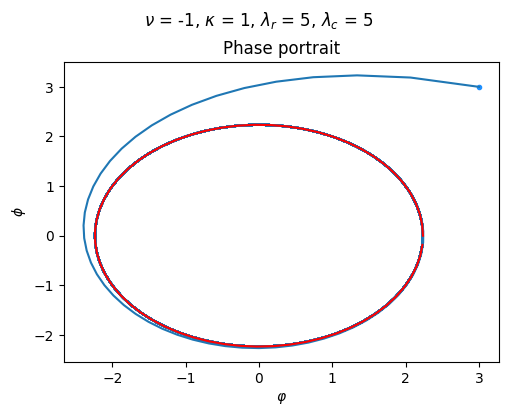

In [29]:
# Deterministic case with nu < 0, lambda_r > 0

# parameters
nu = -1
kappa = 1
lambda_r = 5
lambda_c = 5

# initial condition outside the limiting cycle
phi0 = 3
Phi0 = 3

r0 = np.sqrt(phi0**2 + Phi0**2)
theta0 = np.arctan(Phi0/phi0)

x0 = np.array([r0, theta0])

# time
T = 100
dt = 0.01

t = np.arange(0, T, dt)

# dynamics
x = odeint(f, x0, t, (nu, kappa, lambda_r, lambda_c))

r = x[:, 0]
theta = x[:, 1]

phi = r * np.cos(theta)
Phi = r * np.sin(theta)

# plot
fig, ax = plt.subplots(1, 1, figsize = (5, 4))
fig.subplots_adjust(left = 0.11, right = 0.98, bottom = 0.1, top = 0.85, wspace = 0.25)
fig.suptitle(rf"$\nu$ = {nu}, $\kappa$ = {kappa}, $\lambda_r$ = {lambda_r}, $\lambda_c$ = {lambda_c}")

ax.plot(phi0, Phi0, ".", color = "dodgerblue")
ax.plot(phi, Phi)

# limiting cycle
r = np.sqrt(-lambda_r/nu)
theta = np.arange(0, 2*np.pi, 0.1)

phi = r * np.cos(theta)
Phi = r * np.sin(theta)

ax.plot(phi, Phi, color = "red")

ax.set_title("Phase portrait")
ax.set_xlabel(r"$\varphi$")
ax.set_ylabel(r"$\phi$")

plt.savefig(f"../Figures/Stochasticity/Fig_0.png")

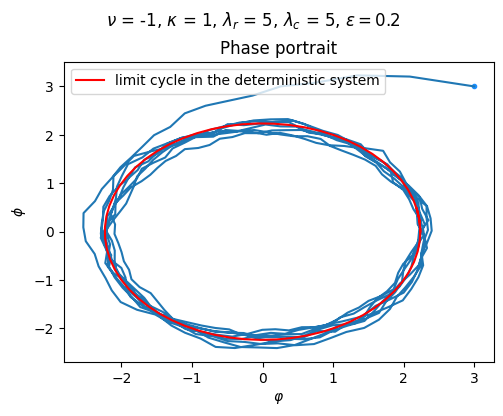

In [28]:
# parameters
f_par = partial(f, nu = -1, kappa = 1, lambda_r = 5, lambda_c = 5)
G_par = partial(G, epsilon = 0.2)

# initial condition
X0 = 3
Y0 = 3

r0 = np.sqrt(X0**2 + Y0**2)
theta0 = np.arctan(Y0/X0)

x0 = np.array([r0, theta0])

# time
T = 5
dt = 0.01

t = np.arange(0, T, dt)

# dynamics
x = sdeint.itoint(f_par, G_par, x0, t)

r = x[:, 0]
theta = x[:, 1]

phi = r * np.cos(theta)
Phi = r * np.sin(theta)

# plot
fig, ax = plt.subplots(1, 1, figsize = (5, 4))
fig.subplots_adjust(left = 0.12, right = 0.98, bottom = 0.1, top = 0.85, wspace = 0.25)
fig.suptitle(rf"$\nu$ = {nu}, $\kappa$ = {kappa}, $\lambda_r$ = {lambda_r}, $\lambda_c$ = {lambda_c}, $\epsilon = 0.2$")

ax.plot(phi0, Phi0, ".", color = "dodgerblue")
ax.plot(phi, Phi)

ax.set_title("Phase portrait")
ax.set_xlabel(r"$\varphi$")
ax.set_ylabel(r"$\phi$")

# limiting cycle
r = np.sqrt(-5/(-1))
theta = np.arange(0, 2.1*np.pi, 0.1)

phi = r * np.cos(theta)
Phi = r * np.sin(theta)

ax.plot(phi, Phi, color = "red", label = "limit cycle in the deterministic system")

ax.legend()

plt.savefig(f"../Figures/Stochasticity/Fig_1.png")